# IMPORT

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image
from tqdm import tqdm



# CONFIG

In [2]:
CLASS_NAMES = {
    1: "Fagus sylvatica",
    2: "Juglans regia",
    3: "Castanea sativa",
    4: "Quercus cerris",
    5: "Alnus glutinosa",
    6: "Fraxinus ornus",
    7: "Picea abies",
    8: "Pinus sylvestris",
    9: "Ailanthus altissima",
    10: "Robinia pseudoacacia",
    11: "Cupressus sempervirens",
    12: "Platanus orientalis"
}

# EDA

In [3]:
source = "../data/Wood Dataset"

# Train folder
train_folder = source + "/Train"

train_df = pd.DataFrame(columns=["image_path", "label"])

for folder in Path(train_folder).iterdir():
    for image_path in Path(folder).iterdir():
        train_df = pd.concat(
            [
                train_df,
                pd.DataFrame(
                    {
                        "image_path": [str(image_path)],
                        "label": [folder.name],
                    }
                ),
            ],
            ignore_index=True,
        )

display(train_df.head())

# Test folder
test_folder = source + "/Test"

test_df = pd.DataFrame(columns=["image_path", "label"])

for image_path in Path(test_folder).iterdir():
    path = Path(image_path).stem
    label = path.split("_")[1]

    test_df = pd.concat(
        [
            test_df,
            pd.DataFrame(
                {
                    "image_path": [str(image_path)],
                    "label": [label],
                }
            ),
        ],
        ignore_index=True,
    )

display(test_df.head())

,image_path,label
0,..\data\Wood Dataset\Train\1\100_1.jpg,1
1,..\data\Wood Dataset\Train\1\101_1.jpg,1
2,..\data\Wood Dataset\Train\1\102_1.jpg,1
3,..\data\Wood Dataset\Train\1\103_1.jpg,1
4,..\data\Wood Dataset\Train\1\104_1.jpg,1


,image_path,label
0,..\data\Wood Dataset\Test\1000_1.jpg,1
1,..\data\Wood Dataset\Test\1001_1.jpg,1
2,..\data\Wood Dataset\Test\1002_1.jpg,1
3,..\data\Wood Dataset\Test\1003_1.jpg,1
4,..\data\Wood Dataset\Test\1004_1.jpg,1


                                    image_path label
count                                     5708  5708
unique                                    5708    12
top     ..\data\Wood Dataset\Train\1\100_1.jpg     3
freq                                         1  1024
label
3     1024
1      936
11     552
12     504
5      464
10     440
6      432
4      400
7      308
8      224
9      224
2      200
Name: count, dtype: int64


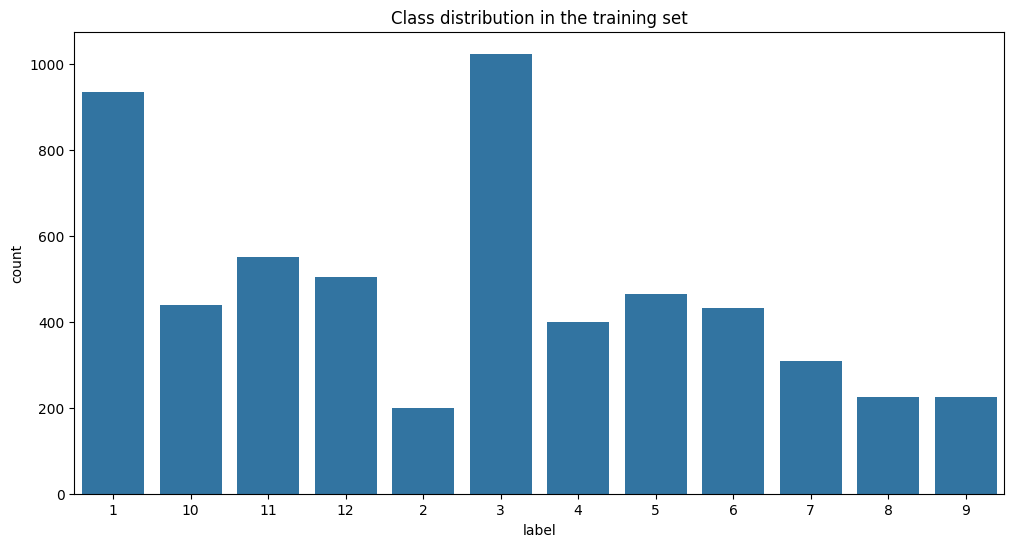

In [4]:
# How many images are there in the training set?
# How many images are there for each class in the training set?

def summary(df: pd.DataFrame):
    print(df.describe())
    print(df["label"].value_counts())

    plt.figure(figsize=(12, 6))
    sns.countplot(x="label", data=df)
    plt.title("Class distribution in the training set")
    plt.show()

summary(train_df)

In [5]:
# Size of the images in the training set


def get_image_properties(image_path):
    image = Image.open(image_path)
    return image.size, image.format, image.mode


def summary_sizes(df: pd.DataFrame):
    size_df = pd.DataFrame(columns=["image_path", "width", "height", "format", "mode"])

    for image_path in tqdm(df["image_path"]):
        image_size, image_format, image_mode = get_image_properties(image_path)
        size_df = pd.concat(
            [
                size_df,
                pd.DataFrame(
                    {
                        "image_path": [image_path],
                        "width": [image_size[0]],
                        "height": [image_size[1]],
                        "format": [image_format],
                        "mode": [image_mode],
                    }
                ),
            ],
            ignore_index=True,
        )
    return size_df


display(summary_sizes(train_df).head())

  0%|          | 0/5708 [00:00<?, ?it/s]

100%|██████████| 5708/5708 [00:04<00:00, 1365.67it/s]


,image_path,width,height,format,mode
0,..\data\Wood Dataset\Train\1\100_1.jpg,200,200,JPEG,RGB
1,..\data\Wood Dataset\Train\1\101_1.jpg,200,200,JPEG,RGB
2,..\data\Wood Dataset\Train\1\102_1.jpg,200,200,JPEG,RGB
3,..\data\Wood Dataset\Train\1\103_1.jpg,200,200,JPEG,RGB
4,..\data\Wood Dataset\Train\1\104_1.jpg,200,200,JPEG,RGB


                                  image_path label
count                                   2836  2836
unique                                  2836    12
top     ..\data\Wood Dataset\Test\1000_1.jpg     3
freq                                       1   508
label
3     508
1     468
11    276
12    252
5     232
10    220
6     216
4     200
7     152
8     108
9     108
2      96
Name: count, dtype: int64


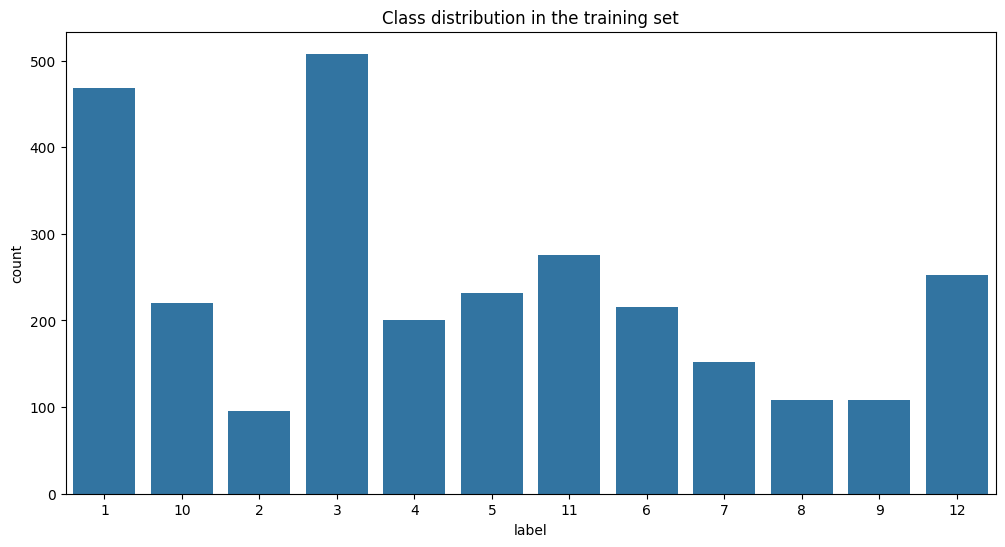

In [6]:
# How many images are there in the test set?
# How many images are there for each class in the test set?

summary(test_df)

In [7]:
# Image size in the test set

display(summary_sizes(test_df).head())

100%|██████████| 2836/2836 [00:01<00:00, 1464.55it/s]


,image_path,width,height,format,mode
0,..\data\Wood Dataset\Test\1000_1.jpg,200,200,JPEG,RGB
1,..\data\Wood Dataset\Test\1001_1.jpg,200,200,JPEG,RGB
2,..\data\Wood Dataset\Test\1002_1.jpg,200,200,JPEG,RGB
3,..\data\Wood Dataset\Test\1003_1.jpg,200,200,JPEG,RGB
4,..\data\Wood Dataset\Test\1004_1.jpg,200,200,JPEG,RGB


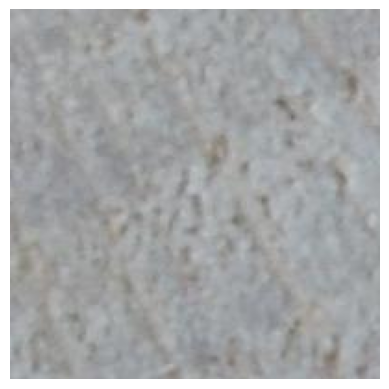

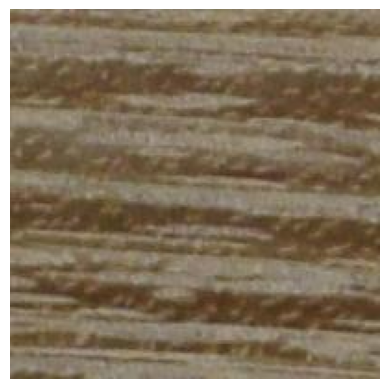

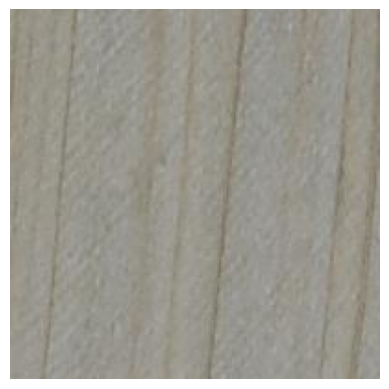

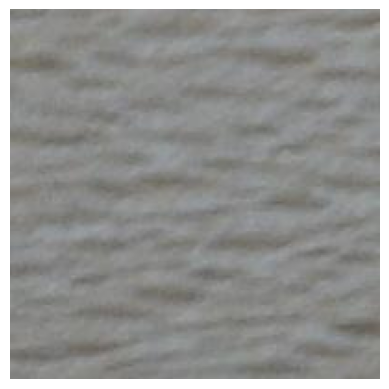

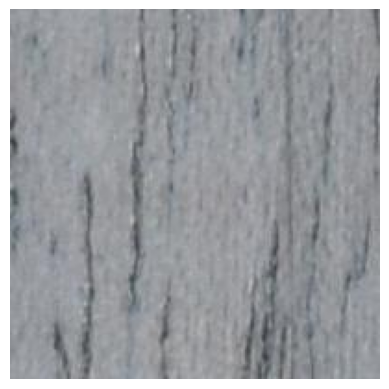

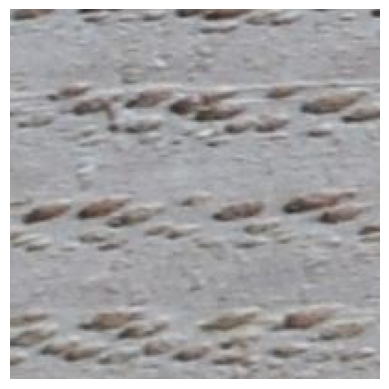

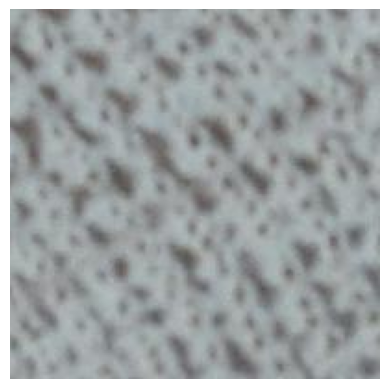

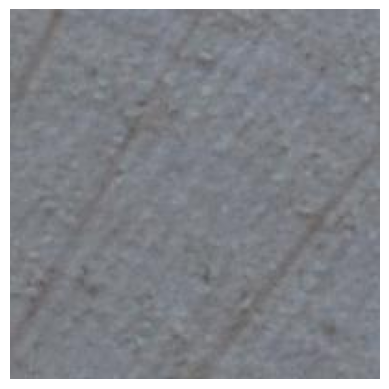

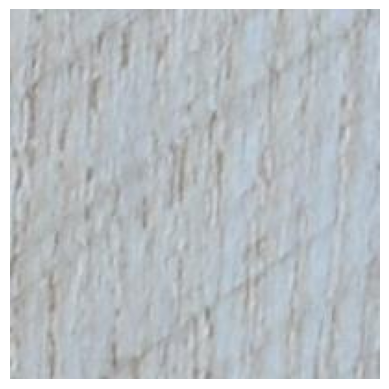

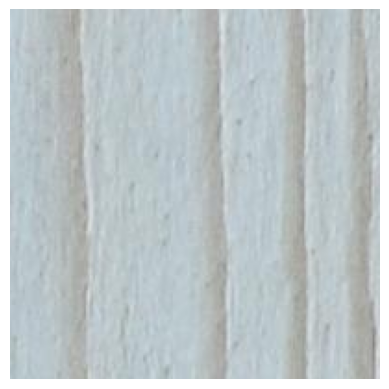

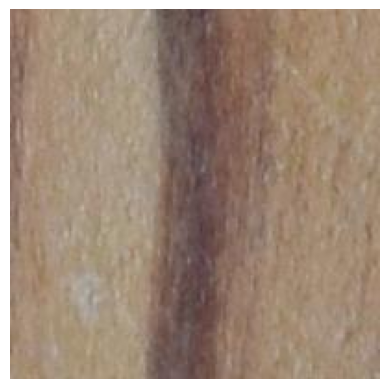

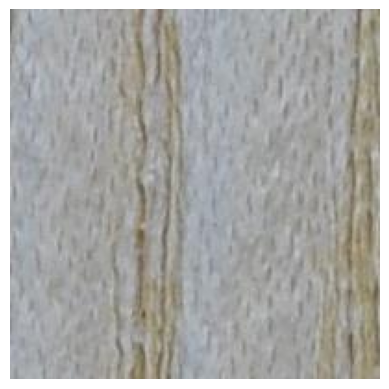

In [8]:
# Images from each class 

samples = train_df.groupby("label").sample(n=1, random_state=42)

for image in samples["image_path"]:
    
    image = Image.open(image)
    plt.imshow(image)
    plt.axis("off")
    plt.show()

In [9]:
# Are there corrupted images in the training set?

def check_corrupted_images(df: pd.DataFrame):
    corrupted_images = []

    for image_path in tqdm(df["image_path"], desc="Checking for corrupted images"):
        try:
            image = Image.open(image_path)
            image.verify()
        except OSError as e:
            corrupted_images.append(image_path)
            print(f"Corrupted image: {image_path}, Error: {e}")

    return corrupted_images

train_corrupted_images = check_corrupted_images(train_df)
display(train_corrupted_images)

test_corrupted_images = check_corrupted_images(test_df)
display(test_corrupted_images)

Checking for corrupted images: 100%|██████████| 5708/5708 [00:00<00:00, 9087.43it/s]


[]

Checking for corrupted images: 100%|██████████| 2836/2836 [00:00<00:00, 9093.96it/s]


[]

In [10]:
# Are there any duplicate images in the training set?

def check_duplicate_images(df: pd.DataFrame):
    image_hashes = {}
    duplicate_images = []

    for image_path in tqdm(df["image_path"], desc="Checking for duplicate images"):
        try:
            with open(image_path, "rb") as f:
                image_hash = hashlib.md5(f.read()).hexdigest()
                if image_hash in image_hashes:
                    duplicate_images.append((image_path, image_hashes[image_hash]))
                else:
                    image_hashes[image_hash] = image_path
        except OSError as e:
            print(f"Error reading image: {image_path}, Error: {e}")

    return duplicate_images

train_duplicate_images = check_duplicate_images(train_df)
test_duplicate_images = check_duplicate_images(test_df)

display(train_duplicate_images)

display(test_duplicate_images)

Checking for duplicate images: 100%|██████████| 2836/2836 [00:00<00:00, 13423.73it/s]


[('..\\data\\Wood Dataset\\Train\\6\\281_6.jpg',
  '..\\data\\Wood Dataset\\Train\\6\\277_6.jpg'),
 ('..\\data\\Wood Dataset\\Train\\6\\282_6.jpg',
  '..\\data\\Wood Dataset\\Train\\6\\278_6.jpg'),
 ('..\\data\\Wood Dataset\\Train\\6\\283_6.jpg',
  '..\\data\\Wood Dataset\\Train\\6\\279_6.jpg'),
 ('..\\data\\Wood Dataset\\Train\\6\\284_6.jpg',
  '..\\data\\Wood Dataset\\Train\\6\\280_6.jpg')]

[]

In [11]:
# Leakage between the training and test sets

def hash_file(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_df["hash"] = [hash_file(p) for p in tqdm(train_df["image_path"])]
test_df["hash"] = [hash_file(p) for p in tqdm(test_df["image_path"])]

leak = set(train_df["hash"]) & set(test_df["hash"])
print(len(leak), "images appear in both train and test")

# remove them from train so the test set stays clean
train_df = train_df[~train_df["hash"].isin(leak)].reset_index(drop=True)

100%|██████████| 2836/2836 [00:00<00:00, 14346.54it/s]

0 images appear in both train and test


In [12]:
# Remove duplicate images from the training set

def remove_duplicate_images(duplicates: list, df: pd.DataFrame) -> pd.DataFrame:
    to_drop = {dup_path for dup_path, _ in duplicates}
    return df[~df["image_path"].isin(to_drop)].reset_index(drop=True)

train_df = remove_duplicate_images(train_duplicate_images, train_df)

print(check_duplicate_images(train_df))   

Checking for duplicate images: 100%|██████████| 5704/5704 [00:00<00:00, 13348.13it/s]

[]


In [13]:
# Export the cleaned dataframes to CSV files

if not Path("../data").exists():
    Path("../data").mkdir(parents=True)

train_df = train_df.drop(columns=["hash"])
test_df = test_df.drop(columns=["hash"])

train_df.to_csv("../data/train.csv", index=False)
test_df.to_csv("../data/test.csv", index=False)